# 01: Baseline: Text Clustering as Classification with a Local LLM

**Goal of this notebook:** reproduce the original method of Huang & He, *Text Clustering as Classification with LLMs*, with one change: the paid GPT-3.5 API is replaced with **Qwen 2.5 (7B)** running locally through Ollama on a consumer GPU (RTX 4060, 8 GB).

**Why start with a baseline?** Every improvement we make later must be measured against something. This notebook gives that reference score, using the original pipeline with no changes to the method itself.

**The original method in two stages:**
1. **Label generation:** the LLM reads the texts in batches of 15 and proposes category names, then merges similar names into one final list.
2. **Classification:** the LLM reads each text and picks one label from that list. Texts with the same label form a cluster.

**Steps:** 0 Setup → 1 Example labels → 2 Generate labels → 2b/2c Check the merge → 3 Classify → 4 Evaluate → 5 Save → Findings

**Running another model:** change `MODEL` in the setup cell. Each model saves its files in its own folder (`generated_labels/<model>/`) and its own rows in `results.csv`, so runs never overwrite each other. (Qwen 2.5, our first model, keeps its files directly in `generated_labels/`.)

**Safe to Run All:** each slow step is skipped if its output file already exists (`REUSE = True`). Set `REUSE = False` to run everything again from scratch.

## 0. Setup
The notebook lives in `/notebooks`, but the scripts and data are in the main project folder, so we move there first.

In [1]:
import os, sys
# Run from the main project folder even though the notebook is in /notebooks
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, time, math, urllib.request
import pandas as pd

DATA = "massive_intent"      # dataset folder inside ./dataset
MODEL = "qwen2.5:7b"          # local LLM in Ollama
SIZE = "small"                 # the paper uses the small split
REUSE = True                   # True: skip slow steps whose output already exists
RERUN_MERGE = False            # True: redo the merge check in 2b and overwrite the label list
# Each model gets its own output folder so runs never overwrite each other.
# qwen2.5:7b (our first run) keeps its files directly in ./generated_labels
OUT = "./generated_labels" if MODEL == "qwen2.5:7b" else f"./generated_labels/{MODEL.replace(':', '_')}"
CHOSEN = "./generated_labels/chosen_labels.json"   # same seed labels for every model (fair comparison)
os.makedirs(OUT, exist_ok=True)
os.makedirs("./results", exist_ok=True)

def out_file(name):
    return f"{OUT}/{DATA}_{SIZE}_{name}.json"

ran = {"labelgen": False, "classify": False}   # tracks what was actually run in this session
print("Working folder:", os.getcwd())

Working folder: c:\Users\itsfr\Desktop\Master\Text-Clustering-via-LLM-main


### Check the data and the LLM
Before spending time on the LLM, we confirm the dataset file exists and Ollama is running with the model.

In [2]:
data_file = f"./dataset/{DATA}/{SIZE}.jsonl"
assert os.path.exists(data_file), f"Dataset not found: {data_file}"
with open(data_file, encoding="utf-8") as f:
    n_texts = sum(1 for _ in f)
print(f"{DATA}: {n_texts} texts")

try:
    tags = json.load(urllib.request.urlopen("http://localhost:11434/api/tags", timeout=5))
    models = [m["name"] for m in tags["models"]]
    print("Ollama is running. Models:", models)
    assert any(m.startswith(MODEL) for m in models), f"Run: ollama pull {MODEL}"
except Exception as e:
    print("Ollama problem:", e)

massive_intent: 2974 texts
Ollama is running. Models: ['llama3.1:8b', 'qwen3:8b', 'qwen2.5:7b']


## 1. Select example labels (20% of the true labels)
**Why:** the original method is not fully unsupervised. It shows the LLM 20% of the true category names as examples, so the generated labels follow the same style. We keep this exactly as in the paper.

**One fix we made:** the original code used `random.choices`, which can pick the same label twice, and set no random seed. We use `random.sample` with a fixed seed, so every run picks the same distinct labels and results are reproducible.

In [3]:
!python select_part_labels.py
with open(CHOSEN, encoding="utf-8") as f:
    chosen = json.load(f)
print("Example labels given to the LLM:", chosen[DATA])

Use dataset ./dataset/arxiv_fine\small.jsonl
Length of dataset: 3674
93
Choose num: 18
Use dataset ./dataset/banking77\small.jsonl
Length of dataset: 3080
77
Choose num: 15
Use dataset ./dataset/clinc\small.jsonl
Length of dataset: 4500
150
Choose num: 30
Use dataset ./dataset/clinc_domain\small.jsonl
Length of dataset: 4500
10
Choose num: 2
Use dataset ./dataset/few_event\small.jsonl
Length of dataset: 4742
34
Choose num: 6
Use dataset ./dataset/few_nerd_nat\small.jsonl
Length of dataset: 3789
58
Choose num: 11
Use dataset ./dataset/few_rel_nat\small.jsonl
Length of dataset: 4480
64
Choose num: 12
Use dataset ./dataset/go_emotion\small.jsonl
Length of dataset: 5940
27
Choose num: 5
Use dataset ./dataset/massive_intent\small.jsonl
Length of dataset: 2974
59
Choose num: 11
Use dataset ./dataset/massive_scenario\small.jsonl
Length of dataset: 2974
18
Choose num: 3
Use dataset ./dataset/mtop_domain\small.jsonl
Length of dataset: 4386
11
Choose num: 2
Use dataset ./dataset/mtop_intent\smal

## 2. Generate labels with the LLM
**What happens:** the texts are shuffled and sent in batches of 15, about `texts / 15` LLM calls (≈199 for massive_scenario). For each batch, the LLM either reuses an existing label or proposes a new one. At the end, **one** extra call asks the LLM to merge similar labels.

Skipped if the output already exists and `REUSE = True`.

In [4]:
if REUSE and os.path.exists(out_file("llm_generated_labels_after_merge")):
    print("Labels already generated: reusing them (set REUSE = False to regenerate).")
    time_labelgen = 0
else:
    t0 = time.time()
    !python label_generation.py --data {DATA} --model {MODEL} --output_path {OUT}
    time_labelgen = time.time() - t0
    ran["labelgen"] = True
    print(f"Label generation time: {time_labelgen/60:.1f} min")

Model: qwen2.5:7b at http://localhost:11434/v1
use_large:  False
Use dataset ./dataset/massive_intent\small.jsonl
Length of dataset: 2974
Total cluster num: 59
JSON file './generated_labels\massive_intent_small_true_labels.json' written.
['alarm query', 'alarm remove', 'alarm set', 'audio volume down', 'audio volume mute', 'audio volume other', 'audio volume up', 'calendar query', 'calendar remove', 'calendar set', 'cooking recipe', 'datetime convert', 'datetime query', 'email addcontact', 'email query', 'email querycontact', 'email sendemail', 'general greet', 'general joke', 'general quirky', 'iot cleaning', 'iot coffee', 'iot hue lightchange', 'iot hue lightdim', 'iot hue lightoff', 'iot hue lighton', 'iot hue lightup', 'iot wemo off', 'iot wemo on', 'lists createoradd', 'lists query', 'lists remove', 'music dislikeness', 'music likeness', 'music query', 'music settings', 'news query', 'play audiobook', 'play game', 'play music', 'play podcasts', 'play radio', 'qa currency', 'qa def

### Inspect the generated labels
**What we check:** how many labels the LLM produced compared with the 18 true clusters. If the number is much larger, the clusters will be split into near-duplicates and the scores will drop.

In [5]:
def load(name):
    with open(out_file(name), encoding="utf-8") as f:
        return json.load(f)
true_labels = load("true_labels")
before = load("llm_generated_labels_before_merge")
after = load("llm_generated_labels_after_merge")
print(f"True clusters: {len(true_labels)} | LLM labels before merge: {len(before)} | after merge: {len(after)}")
print("\nLLM labels after merge:\n", sorted(after))

True clusters: 59 | LLM labels before merge: 156 | after merge: 116

LLM labels after merge:
 ['alarm setting', 'alarms query', 'app open', 'audio book', 'calendar', 'calendar management', 'calendar query', 'calendar task', 'cleaning task', 'clear list', 'cooking query', 'cooking recipe', 'crime news', 'customer service query', 'email query contact', 'email reply', 'email send email', 'email send email', 'email send email', 'finance query', 'food order', 'general query', 'grocery list', 'help complaint', 'iot hue light control', 'iot hue light control', 'iot hue light control', 'latest news', 'light control', 'local business query', 'location query', 'math', 'meeting query', 'music playback', 'music query', 'news query', 'personal query', 'play game', 'play media', 'play music', 'playlist query', 'policy query', 'qa', 'qa biology', 'qa book', 'qa calendar', 'qa cooking', 'qa culinary', 'qa currency', 'qa currency', 'qa date', 'qa date', 'qa date', 'qa date', 'qa definition', 'qa educat

### What we found in our run (Qwen 2.5 7B)
- True clusters: **18**. LLM labels before merge: **76**. After merge: **76**.
- The merge changed **nothing**, and obvious duplicates remained: `alarm` / `alarms` / `alarms_reminders`, `event` / `events` / `upcoming_events`, `query` / `query_info` / `query_information`.

**Decision:** before spending ~30 minutes on classification, find out *why* the merge failed. It was either a parsing error (the answer was not valid JSON, so the code silently kept the original list) or a weak merge by the model.

## 2b. Debug the merge step
This cell reruns **only** the merge call and prints Qwen's raw answer, so we can see which of the two problems it is.

It only runs when `RERUN_MERGE = True`, because the answer can vary slightly between runs and we don't want Run All to overwrite the saved label list.

In [6]:
if RERUN_MERGE:
    import importlib, label_generation as lg
    from types import SimpleNamespace
    importlib.reload(lg)
    lg.MODEL = MODEL
    lg.BASE_URL = "http://localhost:11434/v1"
    client = lg.ini_client(SimpleNamespace(base_url="http://localhost:11434/v1", api_key="ollama"))
    raw = lg.chat(lg.prompt_construct_merge_label(before), client)
    print("RAW ANSWER:\n", raw)
    parsed = lg.parse_json(raw)
    merged = [l for v in parsed.values() for l in (v if isinstance(v, list) else [v])]
    print(f"\nParsed OK: {len(merged)} labels")
    print(sorted(merged))
else:
    merged = after
    print(f"Skipped (RERUN_MERGE = False). Using the saved list: {len(merged)} labels.")

Skipped (RERUN_MERGE = False). Using the saved list: 116 labels.


### What we found
- Qwen's answer **was valid JSON**, so parsing was not the problem.
- But the model **barely merged anything: 76 → 71 labels.** The duplicates listed above were still separate.

**Conclusion:** the original pipeline relies on a strong model (GPT-3.5) to merge 76 labels in a single call. A small 7B local model can't do this reliably. This is a real weakness of the method in low-resource settings, and it becomes the first target of our improvement in notebook 02.

**Decision for the baseline:** keep Qwen's own merge (71 labels) as the honest baseline. We do not fix it here, because the baseline must reflect the original method.

## 2c. Save the merged labels
In the Qwen 2.5 run, the 71 labels from its merge are saved as the label list that Step 3 classifies into.

In [7]:
if RERUN_MERGE:
    with open(out_file("llm_generated_labels_after_merge"), "w", encoding="utf-8") as f:
        json.dump(merged, f, indent=2, ensure_ascii=False)
    print(f"Saved {len(merged)} labels.")
after = merged
print(f"Labels used for classification: {len(after)}")

Labels used for classification: 116


## 3. Classify every text into one label
**What happens:** for each of the 2,974 texts, the LLM receives the full label list and the text, and returns one label. That's **one LLM call per text**, which makes this the slowest and most expensive step of the method. In our run it took about **26 minutes** on the RTX 4060 (~2 texts per second).

If the LLM's answer does not exactly match a label in the list, the text goes to an **"Unsuccessful"** group.

Skipped if the output already exists and `REUSE = True`.

In [8]:
if REUSE and os.path.exists(out_file("find_labels")):
    print("Classification already done: reusing it (set REUSE = False to rerun).")
    time_classify = 0
else:
    t0 = time.time()
    !python given_label_classification.py --data {DATA} --model {MODEL} --output_path {OUT}
    time_classify = time.time() - t0
    ran["classify"] = True
    print(f"Classification time: {time_classify/60:.1f} min")

Model: qwen2.5:7b at http://localhost:11434/v1
False
Use dataset ./dataset/massive_intent\small.jsonl
Length of dataset: 2974
Length of label list: 100
Total sample number: 0	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 200	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 400	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 600	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 800	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 1000	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 1200	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 1400	JSON file './generated_labels\massive_intent_small_find_labels.json' written.
Total sample number: 16

## 4. Evaluate
We compare the predicted clusters with the true categories using the three standard clustering metrics from the paper:
- **ACC:** accuracy after matching each predicted cluster to its best true cluster (Hungarian algorithm).
- **NMI (Normalized Mutual Information):** how much information the clustering shares with the true labels (0 to 1).
- **ARI (Adjusted Rand Index):** agreement on which pairs of texts are grouped together, corrected for chance.

As in the original `evaluate.py`, the "Unsuccessful" texts count as one extra cluster.

In [9]:
import importlib, evaluate as ev
importlib.reload(ev)
gold = ev.load_data("./dataset/", DATA, SIZE == "large")
with open(out_file("find_labels"), encoding="utf-8") as f:
    pred_dict = json.load(f)
y_true_raw = ev.get_labels(gold)
y_pred_raw = ev.get_predict_labels(gold, pred_dict)
y_true_raw = y_true_raw[:len(y_pred_raw)]
y_true, k_true = ev.convert_label_to_ids(y_true_raw)
y_pred, k_pred = ev.convert_label_to_ids(y_pred_raw)
scores = {k: round(float(v), 4) for k, v in ev.clustering_score(y_true, y_pred).items()}
unsuccessful = len(pred_dict.get("Unsuccessful", []))
print(scores)
print(f"Texts the LLM could not classify: {unsuccessful}")

Length of labels: 2974
Number of Clusters: 59
Length of labels: 2974
Number of Clusters: 92
{'ACC': 0.3312, 'ARI': 0.0743, 'NMI': 0.5136}
Texts the LLM could not classify: 1131


### Findings: Massive-I (Qwen 2.5 7B)
- Labels: 156 generated → 116 after the LLM merge (100 unique; true: 59). The merge mostly renamed labels into a `qa ...` pattern and left exact duplicates (`qa date` ×4, `qa general` ×4, `email send email` ×3).
- **1,131 texts (38%) were "Unsuccessful":** the labels are long phrases (e.g. `iot hue light control`) and Qwen's answers often differ slightly, so the strict exact match fails.
- Scores: ACC 33.1, NMI 51.4, ARI 7.4 (paper with GPT-3.5: 71.75 / 78.00 / 56.86). ARI collapses because over a third of the texts end up in one meaningless "Unsuccessful" cluster.
- Classification time: 10.1 min.
- **Conclusion:** on Massive-I the main failure is failed answers (strict matching), not over-splitting. This is exactly what Fix C (rescue by meaning) targets.

## 5. Save the results
Each run is stored as one row in `results/results.csv`, the shared table that all notebooks add to. That way the final comparison builds itself.

If nothing was rerun in this session and a baseline row already exists, we keep the existing row, so the original timings are not overwritten with zeros.

In [10]:
path = "./results/results.csv"
df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
exists = (not df.empty) and ((df["method"] == "baseline") & (df["dataset"] == DATA) & (df["model"] == MODEL)).any()

if exists and not (ran["labelgen"] or ran["classify"]):
    print("Baseline row already saved and nothing was rerun: keeping the existing row.")
else:
    row = {
        "method": "baseline", "dataset": DATA, "model": MODEL, "n_texts": n_texts,
        "true_clusters": k_true, "predicted_clusters": k_pred, **scores,
        "unsuccessful": unsuccessful,
        "llm_calls": math.ceil(n_texts / 15) + 1 + n_texts,   # label generation + merge + classification
        "time_min": round((time_labelgen + time_classify) / 60, 1),
        "date": time.strftime("%Y-%m-%d %H:%M"),
    }
    if exists:
        df = df[~((df["method"] == "baseline") & (df["dataset"] == DATA) & (df["model"] == MODEL))]
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(path, index=False)
    print("Saved.")
df

Saved.


,method,dataset,model,n_texts,true_clusters,predicted_clusters,ACC,ARI,NMI,unsuccessful,llm_calls,time_min,date,threshold,rescue_sim,min_size
0,baseline,massive_scenario,qwen2.5:7b,2974,18,71,0.3988,0.3203,0.5583,175,3174,25.90,2026-11-07 14:03,NaN,NaN,NaN
1,A+B (merge),massive_scenario,qwen2.5:7b,2974,18,27,0.5171,0.4024,0.5794,116,3173,9.60,2026-11-07 18:30,0.55,NaN,NaN
2,A+B+C (merge + rescue),massive_scenario,qwen2.5:7b,2974,18,26,0.5256,0.4128,0.5878,0,3173,9.60,2026-11-07 18:30,0.55,NaN,NaN
3,A+B+D (merge + discovery),massive_scenario,qwen2.5:7b,2974,18,29,0.5245,0.4126,0.5894,0,3173,9.60,2026-11-07 18:30,0.55,0.55,5.0
4,A+B (merge),massive_scenario,qwen2.5:7b,2974,18,21,0.5185,0.4037,0.5583,118,3173,9.50,2026-11-07 18:41,0.60,NaN,NaN
5,A+B+C (merge + rescue),massive_scenario,qwen2.5:7b,2974,18,20,0.5188,0.4078,0.5620,0,3173,9.50,2026-11-07 18:41,0.60,NaN,NaN
6,A+B+D (merge + discovery),massive_scenario,qwen2.5:7b,2974,18,28,0.5195,0.4083,0.5681,0,3173,9.50,2026-11-07 18:41,0.60,0.55,5.0
7,A+B (merge),massive_scenario,qwen2.5:7b,2974,18,37,0.4812,0.3642,0.5791,194,3173,0.00,2026-11-07 18:46,0.50,NaN,NaN
8,A+B+C (merge + rescue),massive_scenario,qwen2.5:7b,2974,18,36,0.4936,0.3857,0.5893,0,3173,0.00,2026-11-07 18:46,0.50,NaN,NaN
9,A+B+D (merge + discovery),massive_scenario,qwen2.5:7b,2974,18,41,0.4939,0.3848,0.5931,0,3173,0.00,2026-11-07 18:46,0.50,0.55,5.0


### Predicted cluster sizes
This chart shows how the texts were spread across the LLM's labels. It's the clearest way to see *why* the scores are what they are.

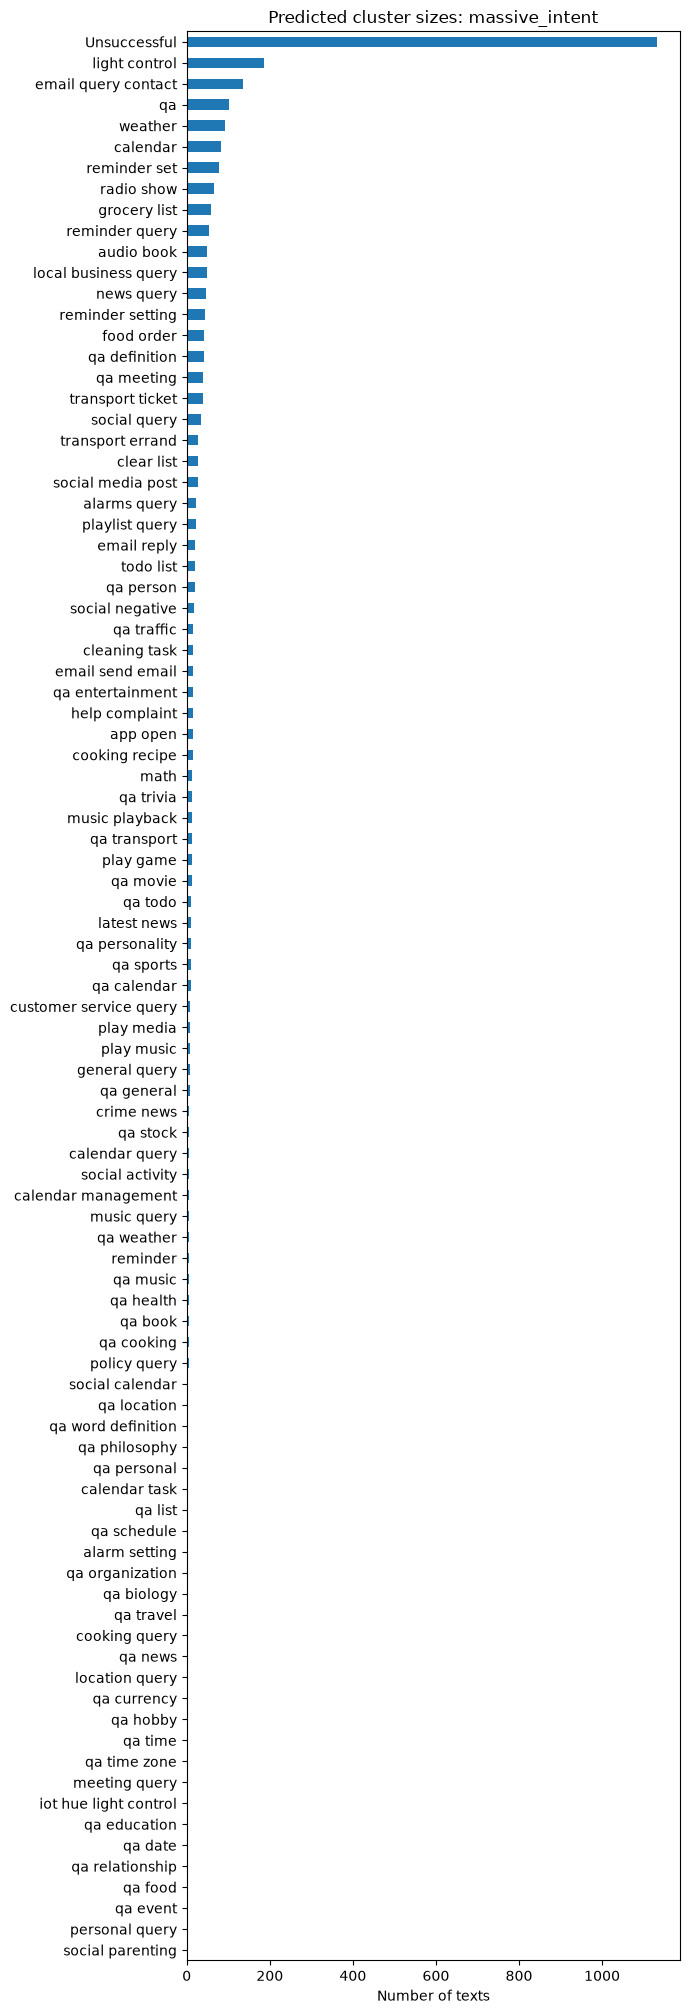

In [11]:
import matplotlib.pyplot as plt
sizes = {k: len(v) for k, v in pred_dict.items() if v}
pd.Series(sizes).sort_values().plot.barh(figsize=(7, max(3, len(sizes) * 0.22)))
plt.title(f"Predicted cluster sizes: {DATA}")
plt.xlabel("Number of texts"); plt.tight_layout(); plt.show()

## Findings from the baseline (Qwen 2.5 7B run, 7 Nov 2026)

| Metric | Score |
|---|---|
| ACC | 0.399 |
| NMI | 0.558 |
| ARI | 0.320 |
| Predicted clusters | 71 (true: 18) |
| Unsuccessful texts | 175 (5.9%) |
| LLM calls | 3,174 |
| Time | ~26 min (classification) |

**Three causes of the low scores, visible in the chart:**
1. **Too many overlapping labels.** The weak merge left near-duplicates (`alarm`, `alarms_reminders`, `alarms_reminders_time`, `reminder`; `music`, `play_music`, `personal_music`, `audio_play`). One true topic gets split across several labels, and ACC can only credit one of them.
2. **Catch-all labels** (`miscellaneous`, `other`, `request`, `information_request`) absorb texts that belong to real topics.
3. **Failed answers:** 175 texts were lost because Qwen answered with a label spelled slightly differently from the list.

**Next step: notebook 02** fixes each cause with one targeted change, reuses the *same* generated labels so the comparison is fair, and measures the effect of each fix.

### Findings: Qwen3 8B baseline
| | Qwen 2.5 7B | Qwen3 8B |
|---|---|---|
| Clusters (true 18) | 71 | 241 |
| ACC | 0.399 | 0.303 |
| ARI | 0.320 | 0.225 |
| NMI | 0.558 | 0.609 |
| Unsuccessful | 175 | 20 |
| Classification time | 26 min | 119 min |

- Qwen3 produced very fine-grained clusters (241). Each is fairly pure, so **NMI is higher**, but **ACC and ARI drop sharply**, because 241 clusters cannot match 18 topics one-to-one.
- Qwen3 follows the label list far better (20 failed answers vs 175).
- With 348 labels in every prompt, classification took 119 min, 4.6× slower than Qwen 2.5.
- **Conclusion:** a newer, stronger model does not fix the method. It understands the texts well, but its label generation over-splits even more, and its own merge does nothing (350 → 348). The merge step is the main bottleneck, which our embedding merge addresses.